# MAE Competencia Regresión 202620

El gerente de la empresa inmobiliaria CasaRoble está interesado en predecir el precio de venta de una vivienda a partir de un conjunto de variables que tiene a su disposición, tales como año de construcción, tamaño, número de parqueaderos, entre otras. Para el efecto cuenta con alguna información que ha sido recolectada durante los últimos diez años sobre el precio de venta de apartamentos y algunas variables explicativas.

Dataset Description
Variables de entrada:

‘# - índice que indica la posición de la observación.

1- SalePrice: precio de venta en dólares.

2- YearBuilt: año de construcción

3- YrSold: año de venta

4- MonthSold: mes de venta

5- Size.sqf: tamaño del apartamento en pies cuadrados

6- Floor: piso en el que se ubica la propiedad

7- HallwayType: tipo de vestíbulo

8- HeatingType: tipo de calefacción.

9- AptManageType: forma en la que se administraba la propiedad

10- N_Parkinglot.Ground: número de estacionamientos en el suelo.

11- N_Parkinglot.Basement: número de estacionamientos en el sótano.

12- TimeToBusStop: tiempo hasta una parada de autobús

13- TimeToSubway: tiempo hasta una estación del subterráneo

14- N_APT: número de apartamentos en el complejo.

15- N_manager: número de personas que atienden las instalaciones del apartamento.

16- N_elevators: número de ascensores.

17- SubwayStation: nombre de la estación más cercana.

18- N_FacilitiesNearBy.PublicOffice: número de oficinas públicas cercanas.

19- N_FacilitiesNearBy.Hospital: número de hospitales cercanos.

20- N_FacilitiesNearBy.Dpartmentstore: número de tiendas departamentales cercanas

21- N_FacilitiesNearBy.Mall: número de centros comerciales cercanos.

22- N_FacilitiesNearBy.ETC. número de otras facilidades cercanas (p.ej. hoteles)

23- N_FacilitiesNearBy.Park. número de parques cercanos.

24- N_SchoolNearBy.Elementary: número de escuelas primarias cercanas.

25- N_SchoolNearBy.Middle: número de escuelas medias cercanas.

26- N_SchoolNearBy.High. número de escuelas secundarias cercanas.

27- N_SchoolNearBy.University. número de universidades cercanas.

28- N_FacilitiesInApt: número de instalaciones del apartamento (p.ej. piscina, gimnasio)

29- N_FacilitiesNearBy.Total: número total de instalaciones cercanas.

30- N_SchoolNearBy.Total: número total de escuelas cercanas.

## 3.1 Contexto y datos

In [56]:
from getpass import getpass
from pathlib import Path

token = getpass("Pegue su token de Kaggle: ").strip()

Path(".env").write_text(
    f"KAGGLE_API_TOKEN={token}\n",
    encoding="utf-8"
)

del token
print("Archivo .env creado.")

Pegue su token de Kaggle: ··········
Archivo .env creado.


In [57]:
import os
from pathlib import Path
from dotenv import load_dotenv

env_path = Path.cwd() / ".env"
if not env_path.is_file():
    raise FileNotFoundError("No se encontro .env")

load_dotenv(env_path, override=True)
if not os.environ.get("KAGGLE_API_TOKEN", "").strip():
    raise ValueError("Falta KAGGLE_API_TOKEN en el archivo .env.")
print("Token cargado desde .env")

Token cargado desde .env


In [58]:
import kagglehub

path = kagglehub.competition_download("mae-competencia-regresion-202620")
data_dir = Path(path)
print("Carpeta de datos:", data_dir)
print("Archivos disponibles:")
for archivo in sorted(data_dir.rglob("*")):
    if archivo.is_file():
        print(" -", archivo.relative_to(data_dir))

Carpeta de datos: /root/.cache/kagglehub/competitions/mae-competencia-regresion-202620
Archivos disponibles:
 - Test real state.csv
 - Train real state.csv


In [59]:
import pandas as pd

# Usa la carpeta obtenida en la celda de descarga.
df_train = pd.read_csv(data_dir / "Train real state.csv")
df_test = pd.read_csv(data_dir / "Test real state.csv")

print("Entrenamiento (filas, columnas):", df_train.shape)
display(df_train.head())
print("Prueba (filas, columnas):", df_test.shape)
print("Columnas de train que no estan en test:", set(df_train.columns) - set(df_test.columns))

Entrenamiento (filas, columnas): (4124, 31)


,id,SalePrice,YearBuilt,YrSold,MonthSold,Size.sqf.,Floor,HallwayType,HeatingType,AptManageType,...,N_FacilitiesNearBy.Mall.,N_FacilitiesNearBy.ETC.,N_FacilitiesNearBy.Park.,N_SchoolNearBy.Elementary.,N_SchoolNearBy.Middle.,N_SchoolNearBy.High.,N_SchoolNearBy.University.,N_FacilitiesInApt,N_FacilitiesNearBy.Total.,N_SchoolNearBy.Total.
0,1,141592,2006,2007,8,814,3,terraced,individual_heating,management_in_trust,...,1,1,0,3,2,2,2,5,6,9
1,2,51327,1985,2007,8,587,8,corridor,individual_heating,self_management,...,1,2,1,2,1,1,0,3,12,4
2,3,48672,1985,2007,8,587,6,corridor,individual_heating,self_management,...,1,2,1,2,1,1,0,3,12,4
3,5,221238,1993,2007,8,1761,3,mixed,individual_heating,management_in_trust,...,1,5,0,4,3,5,5,4,14,17
4,7,78318,1992,2007,8,644,2,mixed,individual_heating,self_management,...,1,1,0,3,3,4,4,3,9,14


Prueba (filas, columnas): (1767, 30)
Columnas de train que no estan en test: {'SalePrice'}


In [60]:
# trabajamos con los datos de train
df_train.info() # miramos el tipo de datos de cada variable y la cantidad de valores nulos

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4124 entries, 0 to 4123
Data columns (total 31 columns):
 #   Column                              Non-Null Count  Dtype 
---  ------                              --------------  ----- 
 0   id                                  4124 non-null   int64 
 1   SalePrice                           4124 non-null   int64 
 2   YearBuilt                           4124 non-null   int64 
 3   YrSold                              4124 non-null   int64 
 4   MonthSold                           4124 non-null   int64 
 5   Size.sqf.                           4124 non-null   int64 
 6   Floor                               4124 non-null   int64 
 7   HallwayType                         4124 non-null   object
 8   HeatingType                         4124 non-null   object
 9   AptManageType                       4124 non-null   object
 10  N_Parkinglot.Ground.                4124 non-null   int64 
 11  N_Parkinglot.Basement.              4124 non-null   int6

In [61]:
df_train.describe().T # miramos un resumen estadístico de las variables numéricas

,count,mean,std,min,25%,50%,75%,max
id,4124.0,2951.804801,1698.599944,1.0,1476.75,2966.5,4419.5,5890.0
SalePrice,4124.0,221687.617847,106353.186576,32743.0,145464.25,207964.0,291150.0,585840.0
YearBuilt,4124.0,2002.974782,8.846158,1978.0,1993.00,2006.0,2008.0,2015.0
YrSold,4124.0,2012.701988,2.903440,2007.0,2010.00,2013.0,2015.0,2017.0
MonthSold,4124.0,6.162706,3.382476,1.0,3.00,6.0,9.0,12.0
Size.sqf.,4124.0,955.909069,376.905448,135.0,644.00,910.0,1149.0,2337.0
Floor,4124.0,12.064743,7.616469,1.0,6.00,11.0,17.0,43.0
N_Parkinglot.Ground.,4124.0,194.698836,218.142679,0.0,11.00,100.0,249.0,713.0
N_Parkinglot.Basement.,4124.0,571.570805,407.517420,0.0,184.00,536.0,798.0,1321.0
N_APT,4124.0,5.630213,2.785791,1.0,3.00,7.0,8.0,13.0


In [62]:
# listado de variables categoricas con la frecuencia de cada valor
categoricas = df_train.select_dtypes(exclude="number").columns
{col: df_train[col].value_counts().to_dict() for col in categoricas}

{'HallwayType': {'terraced': 2505, 'mixed': 1183, 'corridor': 436},
 'HeatingType': {'individual_heating': 3912, 'central_heating': 212},
 'AptManageType': {'management_in_trust': 3876, 'self_management': 248},
 'TimeToBusStop': {'0~5min': 3164, '5min~10min': 924, '10min~15min': 36},
 'TimeToSubway': {'0-5min': 1946,
  '5min~10min': 791,
  '15min~20min': 658,
  '10min~15min': 567,
  'no_bus_stop_nearby': 162},
 'SubwayStation': {'Kyungbuk_uni_hospital': 1176,
  'Myung-duk': 1045,
  'Bangoge': 525,
  'Banwoldang': 514,
  'Sin-nam': 459,
  'no_subway_nearby': 270,
  'Chil-sung-market': 75,
  'Daegu': 60}}

## 3.2 Limpieza y validación

In [63]:
# Valores faltantes y duplicados
print("Valores nulos en total:", int(df_train.isna().sum().sum()))
print("ids repetidos:", int(df_train["id"].duplicated().sum()))

columnas_sin_id = df_train.columns.drop("id")
filas_repetidas = df_train.duplicated(subset=columnas_sin_id, keep=False)
print("Filas identicas a otra (sin contar el id):", int(filas_repetidas.sum()),
      "en", df_train[filas_repetidas].groupby(list(columnas_sin_id)).ngroups, "grupos")
print("Filas que sobran si se dejara una por grupo:",
      int(df_train.duplicated(subset=columnas_sin_id).sum()))

# Sensibilidad: precio con y sin las filas repetidas
sin_repetidas = df_train.drop_duplicates(subset=columnas_sin_id)
print("Precio medio con / sin repetidas:", round(df_train["SalePrice"].mean()), "/", round(sin_repetidas["SalePrice"].mean()))
print("Precio mediano con / sin repetidas:", df_train["SalePrice"].median(), "/", sin_repetidas["SalePrice"].median())

Valores nulos en total: 0
ids repetidos: 0
Filas identicas a otra (sin contar el id): 300 en 108 grupos
Filas que sobran si se dejara una por grupo: 192
Precio medio con / sin repetidas: 221688 / 225857
Precio mediano con / sin repetidas: 207964.0 / 212389.0


In [64]:
# Coherencia entre variables
print("Ventas anteriores al año de construccion:", int((df_train["YrSold"] < df_train["YearBuilt"]).sum()))

instalaciones = ["N_FacilitiesNearBy.PublicOffice.", "N_FacilitiesNearBy.Hospital.",
                 "N_FacilitiesNearBy.Dpartmentstore.", "N_FacilitiesNearBy.Mall.",
                 "N_FacilitiesNearBy.ETC.", "N_FacilitiesNearBy.Park."]
escuelas = ["N_SchoolNearBy.Elementary.", "N_SchoolNearBy.Middle.",
            "N_SchoolNearBy.High.", "N_SchoolNearBy.University."]
print("Total de instalaciones distinto a la suma:",
      int((df_train[instalaciones].sum(axis=1) != df_train["N_FacilitiesNearBy.Total."]).sum()))
print("Total de escuelas distinto a la suma:",
      int((df_train[escuelas].sum(axis=1) != df_train["N_SchoolNearBy.Total."]).sum()))

Ventas anteriores al año de construccion: 0
Total de instalaciones distinto a la suma: 0
Total de escuelas distinto a la suma: 0


In [65]:
# TimeToSubway frente a la estacion mas cercana
pd.crosstab(df_train["TimeToSubway"], df_train["SubwayStation"])

SubwayStation,Bangoge,Banwoldang,Chil-sung-market,Daegu,Kyungbuk_uni_hospital,Myung-duk,Sin-nam,no_subway_nearby
TimeToSubway,,,,,,,,
0-5min,0,470,0,0,815,256,405,0
10min~15min,0,0,0,0,361,206,0,0
15min~20min,0,0,75,0,0,583,0,0
5min~10min,525,44,0,60,0,0,54,108
no_bus_stop_nearby,0,0,0,0,0,0,0,162


In [66]:
# Variables del complejo: se identifican los complejos por año de construccion, estacion y parqueaderos
llave_complejo = ["YearBuilt", "SubwayStation", "N_Parkinglot.Ground.", "N_Parkinglot.Basement."]
complejos = df_train.groupby(llave_complejo)
print("Complejos distintos:", complejos.ngroups)

variables_complejo = ["N_APT", "N_manager", "N_elevators", "HallwayType", "HeatingType",
                      "AptManageType", "TimeToSubway", "TimeToBusStop", "N_FacilitiesInApt",
                      "N_FacilitiesNearBy.Total.", "N_SchoolNearBy.Total."]
print("Complejos con mas de un valor en la variable:",
      {col: int((complejos[col].nunique() > 1).sum()) for col in variables_complejo})

# Complejos registrados sin ascensores y piso maximo vendido en ellos
sin_ascensor = df_train[df_train["N_elevators"] == 0]
print("Ventas en complejos con N_elevators = 0:", len(sin_ascensor))
sin_ascensor.groupby(llave_complejo[:2]).agg(ventas=("Floor", "size"), piso_maximo=("Floor", "max")).reset_index()

Complejos distintos: 26
Complejos con mas de un valor en la variable: {'N_APT': 0, 'N_manager': 0, 'N_elevators': 0, 'HallwayType': 0, 'HeatingType': 0, 'AptManageType': 0, 'TimeToSubway': 0, 'TimeToBusStop': 0, 'N_FacilitiesInApt': 0, 'N_FacilitiesNearBy.Total.': 0, 'N_SchoolNearBy.Total.': 0}
Ventas en complejos con N_elevators = 0: 754


,YearBuilt,SubwayStation,ventas,piso_maximo
0,2005,Bangoge,525,24
1,2006,Kyungbuk_uni_hospital,149,20
2,2014,Banwoldang,44,16
3,2014,no_subway_nearby,36,19


In [67]:
orden_metro = ["0~5min", "5min~10min", "10min~15min", "15min~20min", "no_subway_nearby"]


def limpiar(df):
    df = df.copy()
    # Unificar el formato de TimeToSubway; las filas "no_bus_stop_nearby" se corrigen a "no_subway_nearby".
    df["TimeToSubway"] = df["TimeToSubway"].replace({
        "0-5min": "0~5min",
        "no_bus_stop_nearby": "no_subway_nearby",
    })
    df["TimeToSubway"] = pd.Categorical(df["TimeToSubway"], categories=orden_metro, ordered=True)
    # Variable derivada: antigüedad de la vivienda al momento de la venta
    df["Antiguedad"] = df["YrSold"] - df["YearBuilt"]
    return df

# Variables explicativas seleccionadas (en test no esta SalePrice)
variables_explicativas = [
    "Size.sqf.", "Antiguedad", "YrSold", "Floor",
    "HallwayType", "HeatingType", "AptManageType", "N_Parkinglot.Basement.",
    "TimeToSubway", "SubwayStation", "N_FacilitiesInApt",
    "N_FacilitiesNearBy.Total.", "N_SchoolNearBy.Total.",
]
df_train = limpiar(df_train)
df_reg = df_train.loc[:, ["SalePrice"] + variables_explicativas].copy()

print("Datos para el analisis (filas, columnas):", df_reg.shape)
print("Antiguedad: minimo", df_reg["Antiguedad"].min(), "- maximo", df_reg["Antiguedad"].max(),
      "- ventas en el mismo año de construccion:", int((df_reg["Antiguedad"] == 0).sum()))

Datos para el analisis (filas, columnas): (4124, 14)
Antiguedad: minimo 0 - maximo 39 - ventas en el mismo año de construccion: 235


In [68]:
# Validacion del archivo de prueba con los mismos criterios y la misma limpieza
print("Valores nulos en test:", int(df_test.isna().sum().sum()))
print("ids de test repetidos o presentes en train:", int(df_test["id"].duplicated().sum()),
      int(df_test["id"].isin(df_train["id"]).sum()))
print("Ventas anteriores al año de construccion:", int((df_test["YrSold"] < df_test["YearBuilt"]).sum()))
print("Etiquetas de TimeToSubway en test:", df_test["TimeToSubway"].value_counts().to_dict())
print("Filas 'no_bus_stop_nearby' sin estacion cercana:",
      int(((df_test["TimeToSubway"] == "no_bus_stop_nearby")
           & (df_test["SubwayStation"] == "no_subway_nearby")).sum()),
      "de", int((df_test["TimeToSubway"] == "no_bus_stop_nearby").sum()))

# Categorias de test que no aparecen en train
for col in df_test.select_dtypes(exclude="number").columns:
    nuevas = set(df_test[col]) - set(pd.read_csv(data_dir / "Train real state.csv")[col])
    print(f"{col}: categorias nuevas en test -> {nuevas or 'ninguna'}")

# Complejos de test que no estan en train
complejos_train = set(map(tuple, df_train[llave_complejo].drop_duplicates().to_numpy()))
complejos_test = set(map(tuple, df_test[llave_complejo].drop_duplicates().to_numpy()))
print("Complejos en test:", len(complejos_test), "- no vistos en train:", len(complejos_test - complejos_train))
print("Ventas en complejos con N_elevators = 0 en test:", int((df_test["N_elevators"] == 0).sum()))

df_test = limpiar(df_test)
df_test_reg = df_test.loc[:, ["id"] + variables_explicativas].copy()

# Rangos de test frente a train
numericas = df_reg.select_dtypes(include="number").columns.drop("SalePrice")
pd.DataFrame({
    "Min train": df_reg[numericas].min(), "Max train": df_reg[numericas].max(),
    "Min test": df_test_reg[numericas].min(), "Max test": df_test_reg[numericas].max(),
}).round(1)

Valores nulos en test: 0
ids de test repetidos o presentes en train: 0 0
Ventas anteriores al año de construccion: 0
Etiquetas de TimeToSubway en test: {'0-5min': 834, '5min~10min': 344, '15min~20min': 270, '10min~15min': 242, 'no_bus_stop_nearby': 77}
Filas 'no_bus_stop_nearby' sin estacion cercana: 77 de 77
HallwayType: categorias nuevas en test -> ninguna
HeatingType: categorias nuevas en test -> ninguna
AptManageType: categorias nuevas en test -> ninguna
TimeToBusStop: categorias nuevas en test -> ninguna
TimeToSubway: categorias nuevas en test -> ninguna
SubwayStation: categorias nuevas en test -> ninguna
Complejos en test: 26 - no vistos en train: 0
Ventas en complejos con N_elevators = 0 en test: 331


,Min train,Max train,Min test,Max test
Size.sqf.,135,2337,135,2337
Antiguedad,0,39,0,39
YrSold,2007,2017,2007,2017
Floor,1,43,1,43
N_Parkinglot.Basement.,0,1321,0,1321
N_FacilitiesInApt,1,10,1,10
N_FacilitiesNearBy.Total.,0,16,0,16
N_SchoolNearBy.Total.,0,17,0,17


## 3.3 Medidas de tendencia central y de dispersión

In [69]:
import numpy as np

datos_numericos = df_reg.select_dtypes(include="number").drop(columns=["YrSold"])


def media_recortada(serie, proporcion=0.10):
    # descarta el 10 % de los valores mas bajos y el 10 % de los mas altos
    valores = np.sort(serie.to_numpy())
    k = int(proporcion * len(valores))
    return valores[k:len(valores) - k].mean()


def atipicos_tukey(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    ric = q3 - q1
    return int(((serie < q1 - 1.5 * ric) | (serie > q3 + 1.5 * ric)).sum())


media = datos_numericos.mean()
desviacion = datos_numericos.std(ddof=1)

medidas_descriptivas = pd.DataFrame({
    "N validos": datos_numericos.count(),
    "Media": media,
    "Media recortada 10%": datos_numericos.apply(media_recortada),
    "Mediana": datos_numericos.median(),
    "Moda": pd.Series({col: datos_numericos[col].mode().tolist() for col in datos_numericos}),
    "Desviacion estandar": desviacion,
    "CV (%)": desviacion / media.replace(0, float("nan")) * 100,
    "Minimo": datos_numericos.min(),
    "Primer cuartil (Q1)": datos_numericos.quantile(0.25),
    "Tercer cuartil (Q3)": datos_numericos.quantile(0.75),
    "Maximo": datos_numericos.max(),
    "Rango": datos_numericos.max() - datos_numericos.min(),
    "Rango intercuartil": datos_numericos.quantile(0.75) - datos_numericos.quantile(0.25),
    "Asimetria": datos_numericos.skew(),
    "Atipicos (Tukey)": datos_numericos.apply(atipicos_tukey),
})
medidas_descriptivas.index.name = "Variable"

medidas_descriptivas.round(2).T

Variable,SalePrice,Size.sqf.,Antiguedad,Floor,N_Parkinglot.Basement.,N_FacilitiesInApt,N_FacilitiesNearBy.Total.,N_SchoolNearBy.Total.
N validos,4124,4124,4124,4124,4124,4124,4124,4124
Media,221687.62,955.91,9.73,12.06,571.57,5.83,9.85,10.87
Media recortada 10%,215916.43,922.89,8.67,11.44,554.62,5.7,9.96,10.98
Mediana,207964.0,910.0,7.0,11.0,536.0,5.0,9.0,10.0
Moda,[149274],[914],[3],[7],[536],[4],[9],[17]
Desviacion estandar,106353.19,376.91,8.59,7.62,407.52,2.32,3.45,4.43
CV (%),47.97,39.43,88.29,63.13,71.3,39.81,35.08,40.69
Minimo,32743,135,0,1,0,1,0,0
Primer cuartil (Q1),145464.25,644.0,3.0,6.0,184.0,4.0,8.0,7.0
Tercer cuartil (Q3),291150.0,1149.0,16.0,17.0,798.0,7.0,13.0,15.0


In [70]:
# Limites de Tukey (Q1 - 1,5*RIC y Q3 + 1,5*RIC) y cantidad de atipicos por debajo y por encima.
q1 = datos_numericos.quantile(0.25)
q3 = datos_numericos.quantile(0.75)
limite_inferior = q1 - 1.5 * (q3 - q1)
limite_superior = q3 + 1.5 * (q3 - q1)
pd.DataFrame({
    "Minimo observado": datos_numericos.min(),
    "Limite inferior": limite_inferior,
    "Limite superior": limite_superior,
    "Atipicos bajos": (datos_numericos < limite_inferior).sum(),
    "Maximo observado": datos_numericos.max(),
    "Atipicos altos": (datos_numericos > limite_superior).sum(),
})

,Minimo observado,Limite inferior,Limite superior,Atipicos bajos,Maximo observado,Atipicos altos
Variable,,,,,,
SalePrice,32743,-73064.375,509678.625,0,585840,25
Size.sqf.,135,-113.500,1906.500,0,2337,88
Antiguedad,0,-16.500,35.500,0,39,29
Floor,1,-10.500,33.500,0,43,42
N_Parkinglot.Basement.,0,-737.000,1719.000,0,1321,0
N_FacilitiesInApt,1,-0.500,11.500,0,10,0
N_FacilitiesNearBy.Total.,0,0.500,20.500,49,16,0
N_SchoolNearBy.Total.,0,-5.000,27.000,0,17,0


In [71]:
# Caracteristicas de las viviendas con precio atipico
precio_atipico = df_train[df_train["SalePrice"] > limite_superior["SalePrice"]]
print("Ventas con precio atipico:", len(precio_atipico))
print("Tamaño (pies cuadrados):", precio_atipico["Size.sqf."].value_counts().to_dict())
print("HallwayType:", precio_atipico["HallwayType"].value_counts().to_dict())
print("SubwayStation:", precio_atipico["SubwayStation"].value_counts().to_dict())
print("Año de venta:", precio_atipico["YrSold"].value_counts().to_dict())

# Viviendas mas pequeñas del conjunto
pequenas = df_train[df_train["Size.sqf."] == df_train["Size.sqf."].min()]
print("Viviendas de", df_train["Size.sqf."].min(), "pies cuadrados:", len(pequenas),
      "- años de construccion:", pequenas["YearBuilt"].unique().tolist(),
      "- precio entre", pequenas["SalePrice"].min(), "y", pequenas["SalePrice"].max())

Ventas con precio atipico: 25
Tamaño (pies cuadrados): {1928: 13, 1643: 8, 1519: 3, 1085: 1}
HallwayType: {'terraced': 25}
SubwayStation: {'Kyungbuk_uni_hospital': 24, 'Myung-duk': 1}
Año de venta: {2017: 11, 2015: 8, 2016: 4, 2008: 1, 2009: 1}
Viviendas de 135 pies cuadrados: 18 - años de construccion: [2014] - precio entre 35398 y 60973


In [72]:
print("Asimetria del logaritmo del precio:", round(np.log(df_reg["SalePrice"]).skew(), 2))
precio_pie2 = df_reg["SalePrice"] / df_reg["Size.sqf."]
print("Precio por pie cuadrado: mediana", round(precio_pie2.median(), 1),
      "- Q1", round(precio_pie2.quantile(0.25), 1), "- Q3", round(precio_pie2.quantile(0.75), 1))

Asimetria del logaritmo del precio: -0.67
Precio por pie cuadrado: mediana 227.5 - Q1 178.7 - Q3 277.6


In [73]:
# Ventas por año (YrSold se describe con frecuencias en lugar de media)
ventas_anio = df_reg["YrSold"].value_counts().sort_index()
pd.DataFrame({"Ventas": ventas_anio, "%": (ventas_anio / len(df_reg) * 100).round(1),
              "Precio mediano": df_reg.groupby("YrSold")["SalePrice"].median()})

,Ventas,%,Precio mediano
YrSold,,,
2007,80,1.9,168052.5
2008,275,6.7,176991.0
2009,374,9.1,173008.5
2010,445,10.8,123451.0
2011,384,9.3,180972.5
2012,313,7.6,198230.0
2013,432,10.5,230088.0
2014,471,11.4,244690.0
2015,395,9.6,292035.0


In [74]:
# Frecuencias de las variables categoricas seleccionadas y precio mediano por categoria
tablas = []
for col in ["HallwayType", "HeatingType", "AptManageType", "TimeToSubway", "SubwayStation"]:
    resumen = df_reg.groupby(col, observed=True)["SalePrice"].agg(Ventas="size", Precio_mediano="median")
    resumen["%"] = (resumen["Ventas"] / len(df_reg) * 100).round(1)
    resumen.index = pd.MultiIndex.from_product([[col], resumen.index.astype(str)])
    tablas.append(resumen)
pd.concat(tablas)

Ventas  Precio_mediano     %
HallwayType   corridor                  436         78097.0  10.6
              mixed                    1183        154867.0  28.7
              terraced                 2505        262831.0  60.7
HeatingType   central_heating           212        184512.5   5.1
              individual_heating       3912        209734.0  94.9
AptManageType management_in_trust      3876        215929.0  94.0
              self_management           248        116371.5   6.0
TimeToSubway  0~5min                   1946        277876.0  47.2
              5min~10min                791        158407.0  19.2
              10min~15min               567        163716.0  13.7
              15min~20min               658        138053.0  16.0
              no_subway_nearby          162        201672.0   3.9
SubwayStation Bangoge                   525        169026.0  12.7
              Banwoldang                514        323008.0  12.5
              Chil-sung-market           75         85840.0   1.8
              Daegu                      60         93583.5   1.5
              Kyungbuk_uni_hospital    1176        238938.0  28.5
              Myung-duk                1045        154867.0  25.3
              Sin-nam                   459        247787.0  11.1
              no_subway_nearby          270        207044.0   6.5

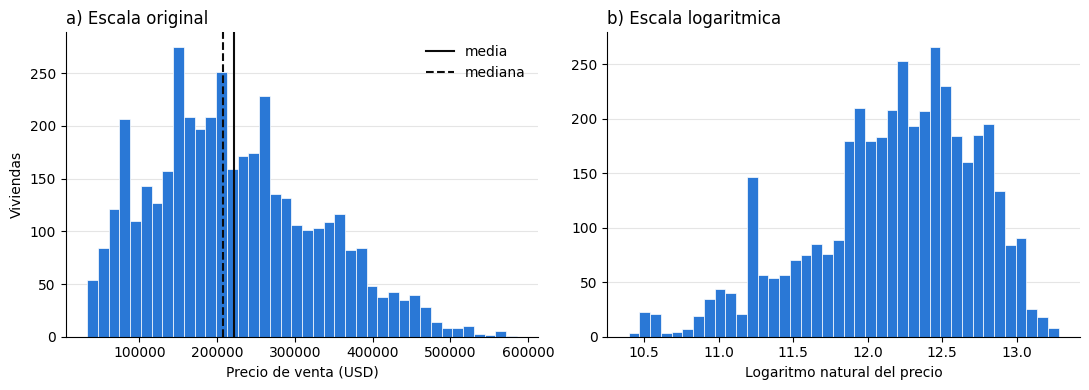

In [75]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
color = "#2a78d6"

axes[0].hist(df_reg["SalePrice"], bins=40, color=color, edgecolor="white", linewidth=0.5)
axes[0].axvline(df_reg["SalePrice"].mean(), color="#0b0b0b", linewidth=1.5, label="media")
axes[0].axvline(df_reg["SalePrice"].median(), color="#0b0b0b", linewidth=1.5, linestyle="--", label="mediana")
axes[0].set_title("a) Escala original", loc="left")
axes[0].set_xlabel("Precio de venta (USD)")
axes[0].set_ylabel("Viviendas")
axes[0].legend(frameon=False)

axes[1].hist(np.log(df_reg["SalePrice"]), bins=40, color=color, edgecolor="white", linewidth=0.5)
axes[1].set_title("b) Escala logaritmica", loc="left")
axes[1].set_xlabel("Logaritmo natural del precio")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

In [76]:
print("Dimensiones de la base:", df_reg.shape)
print("Valores faltantes:", df_reg.isna().sum().sum())

display(df_reg.head())

Dimensiones de la base: (4124, 14)
Valores faltantes: 0


,SalePrice,Size.sqf.,Antiguedad,YrSold,Floor,HallwayType,HeatingType,AptManageType,N_Parkinglot.Basement.,TimeToSubway,SubwayStation,N_FacilitiesInApt,N_FacilitiesNearBy.Total.,N_SchoolNearBy.Total.
0,141592,814,1,2007,3,terraced,individual_heating,management_in_trust,184,10min~15min,Kyungbuk_uni_hospital,5,6,9
1,51327,587,22,2007,8,corridor,individual_heating,self_management,76,5min~10min,Daegu,3,12,4
2,48672,587,22,2007,6,corridor,individual_heating,self_management,76,5min~10min,Daegu,3,12,4
3,221238,1761,14,2007,3,mixed,individual_heating,management_in_trust,536,15min~20min,Myung-duk,4,14,17
4,78318,644,15,2007,2,mixed,individual_heating,self_management,79,15min~20min,Myung-duk,3,9,14


## 3.4 Diagramas de caja

Se compara la distribución del precio de venta entre categorías de
tipo de vestíbulo, cercanía al metro y estación más cercana.
Los gráficos permiten examinar diferencias de mediana, dispersión
y posibles valores atípicos, que se conservan en el análisis.

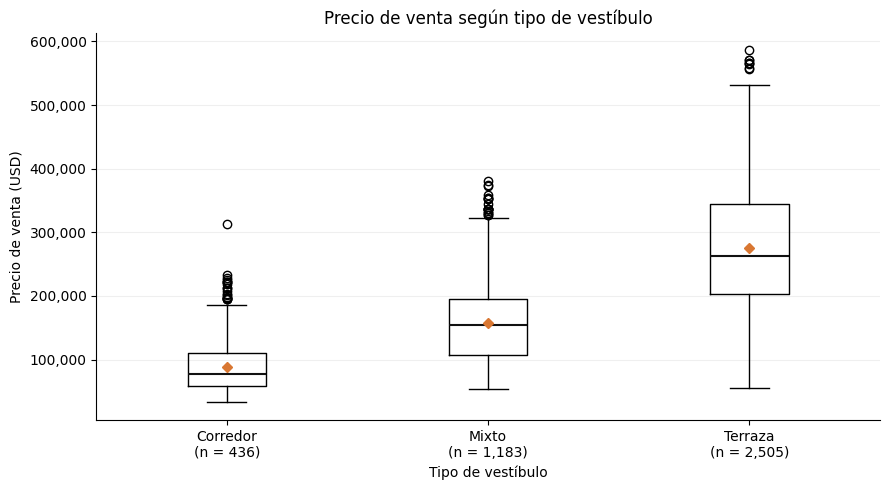

In [77]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

orden = ["corridor", "mixed", "terraced"]
etiquetas = ["Corredor", "Mixto", "Terraza"]
grupos = [
    df_reg.loc[df_reg["HallwayType"] == categoria, "SalePrice"]
    for categoria in orden
]

fig, ax = plt.subplots(figsize=(9, 5))

ax.boxplot(
    grupos,
    tick_labels=[
        f"{etiqueta}\n(n = {len(grupo):,})"
        for etiqueta, grupo in zip(etiquetas, grupos)
    ],
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "#d97732",
        "markeredgecolor": "#d97732",
        "markersize": 5,
    },
    medianprops={"color": "#111111", "linewidth": 1.5},
)

ax.set_title("Precio de venta según tipo de vestíbulo")
ax.set_xlabel("Tipo de vestíbulo")
ax.set_ylabel("Precio de venta (USD)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

In [78]:
resumen_vestibulo = (
    df_reg.groupby("HallwayType")["SalePrice"]
    .agg(
        Viviendas="size",
        Media="mean",
        Mediana="median",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75),
    )
    .reindex(["corridor", "mixed", "terraced"])
)

display(resumen_vestibulo.round(2))

,Viviendas,Media,Mediana,Q1,Q3
HallwayType,,,,,
corridor,436,88567.37,78097.0,57964.0,110619.0
mixed,1183,158268.53,154867.0,107743.0,195575.0
terraced,2505,274807.46,262831.0,203539.0,344247.0


Los precios presentan diferencias entre los tipos de vestíbulo. La categoría terraced registra la mediana más alta, seguida de mixed y corridor. También se observa una mayor dispersión absoluta en terraced. Los tamaños de los grupos son distintos: 2.505, 1.183 y 436 viviendas, respectivamente.

Estas diferencias son descriptivas: no demuestran que el tipo de vestíbulo determine el precio. Pueden estar relacionadas con el área, la antigüedad, la ubicación y otras características de los conjuntos residenciales. Los puntos fuera de los bigotes se conservan, pues su condición de atípicos dentro de cada grupo no implica que sean errores.

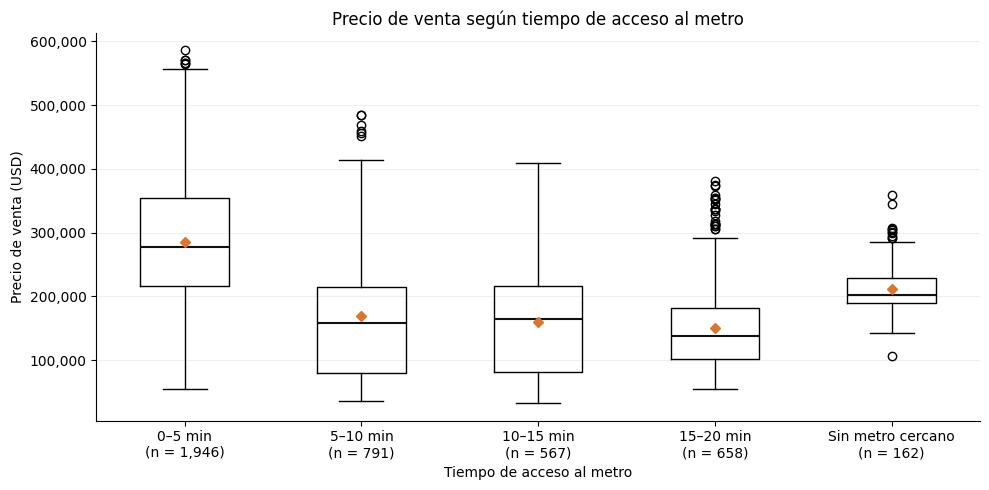

,Viviendas,Media,Mediana,Q1,Q3
TimeToSubway,,,,,
0~5min,1946,285987.71,277876.0,216814.00,353982.00
5min~10min,791,168849.43,158407.0,80088.00,215265.00
10min~15min,567,160078.95,163716.0,81636.50,216814.00
15min~20min,658,150683.17,138053.0,102101.00,181415.00
no_subway_nearby,162,211317.72,201672.0,190145.75,228981.75


In [79]:
orden_metro = [
    "0~5min", "5min~10min", "10min~15min",
    "15min~20min", "no_subway_nearby"
]

etiquetas_metro = [
    "0–5 min", "5–10 min", "10–15 min",
    "15–20 min", "Sin metro cercano"
]

grupos_metro = [
    df_reg.loc[df_reg["TimeToSubway"] == categoria, "SalePrice"]
    for categoria in orden_metro
]

fig, ax = plt.subplots(figsize=(10, 5))

ax.boxplot(
    grupos_metro,
    tick_labels=[
        f"{etiqueta}\n(n = {len(grupo):,})"
        for etiqueta, grupo in zip(etiquetas_metro, grupos_metro)
    ],
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "#d97732",
        "markeredgecolor": "#d97732",
        "markersize": 5,
    },
    medianprops={"color": "#111111", "linewidth": 1.5},
)

ax.set_title("Precio de venta según tiempo de acceso al metro")
ax.set_xlabel("Tiempo de acceso al metro")
ax.set_ylabel("Precio de venta (USD)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

resumen_metro = (
    df_reg.groupby("TimeToSubway", observed=True)["SalePrice"]
    .agg(
        Viviendas="size",
        Media="mean",
        Mediana="median",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75),
    )
    .reindex(orden_metro)
)

display(resumen_metro.round(2))

### Interpretación: tiempo de acceso al metro

Las viviendas situadas a 0–5 minutos del metro presentan el precio
mediano más alto (USD 277.876). Este grupo reúne 1.946 ventas,
equivalentes al 47,2 % de las observaciones.

Las medianas son USD 158.407 para 5–10 minutos, USD 163.716 para
10–15 minutos y USD 138.053 para 15–20 minutos. Por tanto, no se
observa una disminución estrictamente progresiva del precio al
aumentar el tiempo de acceso.

El grupo sin metro cercano presenta una mediana de USD 201.672
y una menor dispersión intercuartílica que los otros grupos.
Comprende 162 ventas, por lo que representa una parte pequeña
del conjunto.

Estas diferencias muestran una asociación descriptiva entre
accesibilidad y precio. No permiten atribuirlas exclusivamente
a la cercanía al metro, porque los grupos también pueden diferir
en área, antigüedad y características del conjunto residencial.

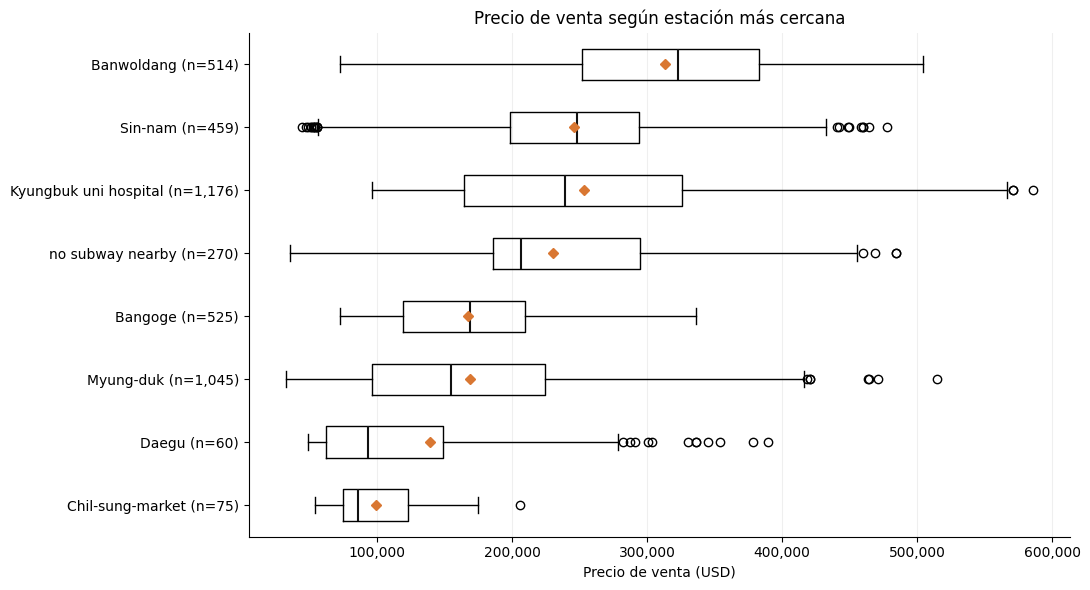

,Viviendas,Media,Mediana,Q1,Q3
SubwayStation,,,,,
Chil-sung-market,75,99462.65,85840.0,74557.00,123008.00
Daegu,60,139185.28,93583.5,61946.00,148672.25
Myung-duk,1045,168954.86,154867.0,96460.00,224690.00
Bangoge,525,167775.51,169026.0,119469.00,209734.00
no_subway_nearby,270,230267.66,207044.0,186282.50,294690.00
Kyungbuk_uni_hospital,1176,253338.76,238938.0,164601.00,325663.00
Sin-nam,459,245701.21,247787.0,198672.50,293805.00
Banwoldang,514,313061.17,323008.0,251879.75,382963.75


In [80]:
orden_estaciones = (
    df_reg.groupby("SubwayStation")["SalePrice"]
    .median()
    .sort_values()
    .index
)

grupos_estaciones = [
    df_reg.loc[df_reg["SubwayStation"] == estacion, "SalePrice"]
    for estacion in orden_estaciones
]

fig, ax = plt.subplots(figsize=(11, 6))

ax.boxplot(
    grupos_estaciones,
    vert=False,
    tick_labels=[
        f"{estacion.replace('_', ' ')} (n={len(grupo):,})"
        for estacion, grupo in zip(
            orden_estaciones, grupos_estaciones
        )
    ],
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "#d97732",
        "markeredgecolor": "#d97732",
        "markersize": 5,
    },
    medianprops={"color": "#111111", "linewidth": 1.5},
)

ax.set_title("Precio de venta según estación más cercana")
ax.set_xlabel("Precio de venta (USD)")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="x", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

resumen_estaciones = (
    df_reg.groupby("SubwayStation")["SalePrice"]
    .agg(
        Viviendas="size",
        Media="mean",
        Mediana="median",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75),
    )
    .reindex(orden_estaciones)
)

display(resumen_estaciones.round(2))

### Interpretación: estación más cercana

Los precios medianos varían entre las estaciones: desde USD 85.840
en Chil-sung-market hasta USD 323.008 en Banwoldang. Las distribuciones
también presentan diferencias de dispersión y solapamiento.

Los grupos tienen tamaños desiguales. Daegu y Chil-sung-market
comprenden 60 y 75 ventas, respectivamente, frente a 1.176 en
Kyungbuk_uni_hospital. Esto debe tenerse presente al comparar
sus distribuciones.

La estación más cercana permite describir diferencias de ubicación,
pero no aislar su efecto sobre el precio: los grupos pueden diferir
en área, antigüedad y características de los conjuntos residenciales.

## 3.5 Tablas de contingencia

Se examinan relaciones entre características categóricas mediante
frecuencias y porcentajes por fila. Primero se contrasta la coherencia
entre el tiempo de acceso al metro y la estación más cercana.
Después se estudia cómo se distribuyen los tipos de vestíbulo entre
los intervalos de acceso al metro.

In [81]:
# 1. Coherencia entre tiempo de acceso y estación
tabla_metro_estacion = pd.crosstab(
    df_reg["TimeToSubway"],
    df_reg["SubwayStation"],
    dropna=False,
)

print("Frecuencias: tiempo de acceso × estación")
display(tabla_metro_estacion)

sin_estacion = df_reg["SubwayStation"].eq("no_subway_nearby")
sin_acceso = df_reg["TimeToSubway"].eq("no_subway_nearby")

print(
    "Sin estación cercana, pero con tiempo de acceso registrado:",
    int((sin_estacion & ~sin_acceso).sum()),
)

# 2. Tipo de vestíbulo según tiempo de acceso
tabla_vestibulo_metro = pd.crosstab(
    df_reg["TimeToSubway"],
    df_reg["HallwayType"],
).reindex(
    index=orden_metro,
    columns=["corridor", "mixed", "terraced"],
    fill_value=0,
)

porcentajes_vestibulo_metro = (
    tabla_vestibulo_metro
    .div(tabla_vestibulo_metro.sum(axis=1), axis=0)
    .mul(100)
)

print("\nFrecuencias: tiempo de acceso × tipo de vestíbulo")
display(tabla_vestibulo_metro)

print("\nPorcentajes por fila: cada fila suma 100 %")
display(porcentajes_vestibulo_metro.round(1))

Frecuencias: tiempo de acceso × estación


SubwayStation,Bangoge,Banwoldang,Chil-sung-market,Daegu,Kyungbuk_uni_hospital,Myung-duk,Sin-nam,no_subway_nearby
TimeToSubway,,,,,,,,
0~5min,0,470,0,0,815,256,405,0
5min~10min,525,44,0,60,0,0,54,108
10min~15min,0,0,0,0,361,206,0,0
15min~20min,0,0,75,0,0,583,0,0
no_subway_nearby,0,0,0,0,0,0,0,162


Sin estación cercana, pero con tiempo de acceso registrado: 108

Frecuencias: tiempo de acceso × tipo de vestíbulo


HallwayType,corridor,mixed,terraced
TimeToSubway,,,
0~5min,51,0,1895
5min~10min,179,525,87
10min~15min,206,0,361
15min~20min,0,658,0
no_subway_nearby,0,0,162



Porcentajes por fila: cada fila suma 100 %


HallwayType,corridor,mixed,terraced
TimeToSubway,,,
0~5min,2.6,0.0,97.4
5min~10min,22.6,66.4,11.0
10min~15min,36.3,0.0,63.7
15min~20min,0.0,100.0,0.0
no_subway_nearby,0.0,0.0,100.0


### Interpretación de las tablas de contingencia

La composición por tipo de vestíbulo cambia entre los intervalos
de acceso al metro. Las viviendas de tipo terraced representan
el 97,4 % del grupo situado a 0–5 minutos, mientras que todas las
viviendas a 15–20 minutos son de tipo mixed.

Por tanto, las diferencias de precio entre intervalos de acceso
pueden estar relacionadas también con las características de las
viviendas y los conjuntos que los integran. Las tablas no permiten
separar esas asociaciones ni establecer efectos causales.

El cruce entre estación y tiempo de acceso también revela diferencias
entre las etiquetas de ausencia de metro cercano. Se conservan los
valores registrados mientras no exista información que justifique
su corrección.

In [82]:
from scipy.stats import chi2_contingency
import numpy as np

# Se usan conteos, sin incluir filas ni columnas de totales.
tabla = tabla_vestibulo_metro.loc[
    tabla_vestibulo_metro.sum(axis=1) > 0,
    tabla_vestibulo_metro.sum(axis=0) > 0,
]

chi2, p, gl, esperadas = chi2_contingency(
    tabla,
    correction=False,
)

n = tabla.to_numpy().sum()
v_cramer = np.sqrt(
    chi2 / (n * min(tabla.shape[0] - 1, tabla.shape[1] - 1))
)

print(f"Ventas analizadas: {n}")
print(f"Chi-cuadrado: {chi2:.2f}")
print(f"Grados de libertad: {gl}")
print(f"Valor p bajo independencia de observaciones: {p:.3e}")
print(f"V de Cramér: {v_cramer:.3f}")
print(f"Frecuencia esperada mínima: {esperadas.min():.2f}")
print(f"Celdas con frecuencia esperada menor que 5: {(esperadas < 5).sum()}")

Ventas analizadas: 4124
Chi-cuadrado: 4187.09
Grados de libertad: 8
Valor p bajo independencia de observaciones: 0.000e+00
V de Cramér: 0.712
Frecuencia esperada mínima: 17.13
Celdas con frecuencia esperada menor que 5: 0


La asociación entre tiempo de acceso al metro y tipo de vestíbulo
es marcada (V de Cramér = 0,712; χ² = 4.187,09; gl = 8).
Todas las frecuencias esperadas superan cinco.

Bajo el supuesto de independencia entre observaciones, la prueba
arroja p < 0,001. Sin embargo, varias ventas comparten características
del mismo conjunto residencial, por lo que la inferencia debe
interpretarse con cautela.

El resultado respalda la lectura de las tablas: los intervalos de
acceso al metro tienen una composición diferente de tipos de vivienda.
Por ello, las diferencias de precio observadas no pueden atribuirse
exclusivamente a la accesibilidad.

## 3.6 Diagramas de dispersión y correlación

Se examina la relación del precio con el área, la antigüedad y el piso.
Los puntos se distinguen por tipo de vestíbulo para identificar
patrones que podrían quedar ocultos al analizar todas las ventas juntas.

Se calculan correlaciones de Pearson, que resumen asociaciones
lineales, y de Spearman, que resumen asociaciones monótonas.
Estos coeficientes no establecen relaciones causales.

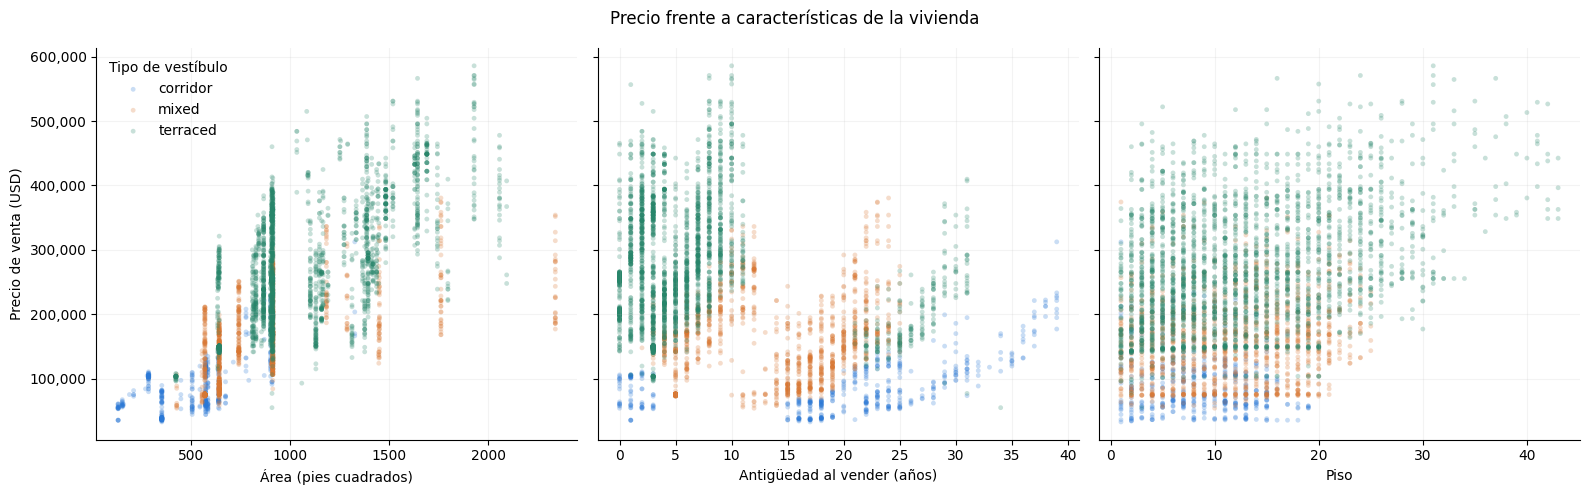

,Pearson,Spearman
Variable,,
Size.sqf.,0.707,0.709
N_FacilitiesInApt,0.499,0.506
N_Parkinglot.Basement.,0.461,0.421
N_FacilitiesNearBy.Total.,-0.413,-0.392
N_SchoolNearBy.Total.,-0.379,-0.383
YrSold,0.368,0.372
Floor,0.344,0.276
Antiguedad,-0.331,-0.297


In [83]:
variables_dispersion = {
    "Size.sqf.": "Área (pies cuadrados)",
    "Antiguedad": "Antigüedad al vender (años)",
    "Floor": "Piso",
}

colores = {
    "corridor": "#2a78d6",
    "mixed": "#d97732",
    "terraced": "#27856a",
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for ax, (variable, etiqueta) in zip(
    axes, variables_dispersion.items()
):
    for categoria, color in colores.items():
        grupo = df_reg[df_reg["HallwayType"] == categoria]

        ax.scatter(
            grupo[variable],
            grupo["SalePrice"],
            s=12,
            alpha=0.25,
            color=color,
            label=categoria,
            edgecolors="none",
        )

    ax.set_xlabel(etiqueta)
    ax.yaxis.set_major_formatter(
        StrMethodFormatter("{x:,.0f}")
    )
    ax.grid(alpha=0.15)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Precio de venta (USD)")
axes[0].legend(title="Tipo de vestíbulo", frameon=False)

fig.suptitle("Precio frente a características de la vivienda")
plt.tight_layout()
plt.show()

# Correlaciones con el precio de todas las explicativas numéricas.
explicativas_numericas = (
    df_reg.select_dtypes(include="number")
    .columns.drop("SalePrice")
)

correlaciones_precio = pd.DataFrame({
    "Pearson": [
        df_reg[variable].corr(df_reg["SalePrice"], method="pearson")
        for variable in explicativas_numericas
    ],
    "Spearman": [
        df_reg[variable].corr(df_reg["SalePrice"], method="spearman")
        for variable in explicativas_numericas
    ],
}, index=explicativas_numericas)

correlaciones_precio.index.name = "Variable"
correlaciones_precio = correlaciones_precio.loc[
    correlaciones_precio["Pearson"]
    .abs()
    .sort_values(ascending=False)
    .index
]

display(correlaciones_precio.round(3))

### Interpretación: dispersión y correlación con el precio

El área presenta la asociación positiva más alta con el precio
(Pearson = 0,707; Spearman = 0,709). Las viviendas de mayor tamaño
tienden a venderse por valores superiores, aunque existe dispersión:
viviendas con áreas similares pueden tener precios diferentes.

El número de instalaciones del conjunto presenta una correlación
positiva de 0,499 con el precio, y los estacionamientos en sótano,
de 0,461. Estas asociaciones pueden reflejar diferencias entre
conjuntos residenciales; no deben interpretarse como efectos
individuales sobre el precio.

El piso presenta una asociación positiva (Pearson = 0,344), mientras
que la antigüedad se relaciona negativamente con el precio
(Pearson = −0,331). Ninguna de estas relaciones es determinista.

El año de venta presenta una correlación positiva de 0,368. Las
comparaciones de precios deben considerar el periodo de la venta,
además de las características de las viviendas.

Los totales de instalaciones y escuelas cercanas presentan
correlaciones negativas con el precio. Esto no demuestra que esos
servicios reduzcan el valor de una vivienda: las asociaciones
pueden reflejar diferencias de ubicación y composición de los grupos.

Los coeficientes describen relaciones bivariadas. Su interpretación
debe contrastarse con los diagramas y con las relaciones entre
las propias variables explicativas.

Diez parejas con mayor correlación absoluta:


,Variable 1,Variable 2,Pearson,Magnitud
22,N_Parkinglot.Basement.,N_FacilitiesInApt,0.831,0.831
27,N_FacilitiesNearBy.Total.,N_SchoolNearBy.Total.,0.808,0.808
9,Antiguedad,N_Parkinglot.Basement.,-0.545,0.545
10,Antiguedad,N_FacilitiesInApt,-0.544,0.544
11,Antiguedad,N_FacilitiesNearBy.Total.,0.372,0.372
18,Floor,N_Parkinglot.Basement.,0.328,0.328
12,Antiguedad,N_SchoolNearBy.Total.,0.279,0.279
6,Size.sqf.,N_SchoolNearBy.Total.,-0.277,0.277
19,Floor,N_FacilitiesInApt,0.266,0.266
5,Size.sqf.,N_FacilitiesNearBy.Total.,-0.265,0.265


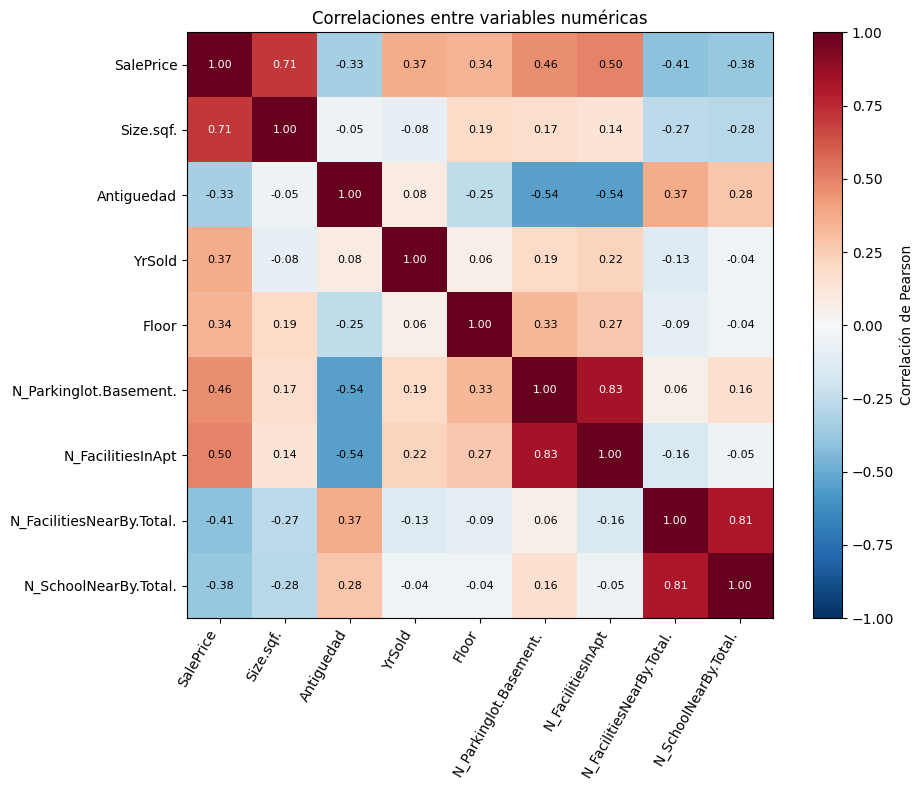

In [84]:
# Correlaciones entre las explicativas numéricas.
matriz_explicativas = df_reg[explicativas_numericas].corr()

# Cada pareja aparece una sola vez.
mascara = np.triu(
    np.ones(matriz_explicativas.shape, dtype=bool),
    k=1,
)

pares = (
    matriz_explicativas.where(mascara)
    .stack()
    .rename("Pearson")
    .reset_index()
)

pares.columns = ["Variable 1", "Variable 2", "Pearson"]
pares["Magnitud"] = pares["Pearson"].abs()
pares = pares.sort_values("Magnitud", ascending=False)

print("Diez parejas con mayor correlación absoluta:")
display(pares.head(10).round(3))

# Mapa de correlaciones de respuesta y explicativas numéricas.
columnas_mapa = ["SalePrice"] + list(explicativas_numericas)
matriz = df_reg[columnas_mapa].corr()

fig, ax = plt.subplots(figsize=(10, 8))

imagen = ax.imshow(matriz, cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(len(matriz)), labels=matriz.columns,
              rotation=60, ha="right")
ax.set_yticks(range(len(matriz)), labels=matriz.index)

for i in range(len(matriz)):
    for j in range(len(matriz)):
        valor = matriz.iloc[i, j]
        ax.text(
            j, i, f"{valor:.2f}",
            ha="center", va="center", fontsize=8,
            color="white" if abs(valor) > 0.6 else "black",
        )

fig.colorbar(imagen, ax=ax, label="Correlación de Pearson")
ax.set_title("Correlaciones entre variables numéricas")
plt.tight_layout()
plt.show()

### Asociación entre variables explicativas

Los parqueaderos en sótano y las instalaciones del conjunto presentan
una correlación positiva elevada (r = 0,831). También están asociados
el total de instalaciones cercanas y el total de escuelas cercanas
(r = 0,808). Estas parejas podrían aportar información parcialmente
redundante en un modelo de regresión.

La antigüedad se relaciona negativamente con los parqueaderos en
sótano (r = −0,545) y las instalaciones del conjunto (r = −0,544).
En esta muestra, las viviendas más antiguas tienden a pertenecer
a conjuntos con menores valores de estas características.

Estas asociaciones deben considerarse en la modelación posterior.
No justifican eliminar variables automáticamente ni constituyen
por sí solas un diagnóstico completo de multicolinealidad.

### Síntesis del análisis

El área presenta la asociación bivariada más alta con el precio.
Los diagramas de caja muestran diferencias de precio entre tipos
de vestíbulo, intervalos de acceso al metro y estaciones cercanas.

Las tablas de contingencia evidencian que accesibilidad y tipo de
vestíbulo están asociados. Por ello, sus relaciones con el precio
deben estudiarse conjuntamente y considerando el año de venta,
la antigüedad y las características del conjunto residencial.